In [1]:
import os
import random
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torchvision import transforms
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix

c:\Users\eds\Documents\NN\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
def download_data():
    if not os.path.exists('tiny-imagenet-200'):
        urllib.request.urlretrieve('http://cs231n.stanford.edu/tiny-imagenet-200.zip', 'tiny-imagenet-200.zip')
        file = zipfile.ZipFile('tiny-imagenet-200.zip', 'r')
        file.extractall()

download_data()

In [2]:
class TinyImageNetDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]

        with Image.open(path) as img:
            img = img.convert('RGB')
            if self.transform:
                img = self.transform(img)

        return img, label

In [3]:
DATA_DIR = Path('tiny-imagenet-200')
root = Path(DATA_DIR)
CHECKPOINT_DIR = Path('./checkpoints')
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

classes = sorted(p.name for p in (root / 'train').iterdir() if p.is_dir())
class_to_idx = {name: i for i, name in enumerate(classes)}

train_samples = [
    (path, label)
    for name, label in class_to_idx.items()
    for path in (root / 'train' / name / 'images').glob('*.JPEG')
]

with open(root / 'val' / 'val_annotations.txt') as f:
    val_samples = [
        (root / 'val' / 'images' / filename, class_to_idx[wnid])
        for filename, wnid, *_ in (
            line.strip().split('\t') for line in f
        )
    ]

In [4]:
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1))], p=0.4),
    transforms.RandomApply([transforms.ColorJitter(brightness=0.2, contrast=0.2)], p=0.2),
    transforms.ToTensor(),
])
val_transform = transforms.ToTensor()

train_dataset = TinyImageNetDataset(
    train_samples,
    transform=train_transform
)

val_dataset = TinyImageNetDataset(
    val_samples,
    transform=val_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=512,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=512,
    shuffle=False
)

In [5]:
class TinyCNN(nn.Module):
    def __init__(self, num_classes=200):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.BatchNorm2d(32, momentum=0.1), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout(0.2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64, momentum=0.1), nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1), nn.BatchNorm2d(64, momentum=0.1), nn.ReLU(),
            nn.MaxPool2d(2), nn.Dropout(0.15),

            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128, momentum=0.1), nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1), nn.BatchNorm2d(128, momentum=0.1), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1)),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(128, 128), nn.BatchNorm1d(128, momentum=0.1),
            nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_CLASSES = 200

model = TinyCNN(NUM_CLASSES).to(DEVICE)

In [13]:
@torch.no_grad()
def evaluate(model, data_loader, criterion, device=DEVICE, return_predictions=False):
    model.eval()

    total_loss, total_correct, total_count = 0.0, 0, 0
    y_true, y_pred = [], []

    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        logits = model(x)
        predictions = logits.argmax(dim=1)

        total_loss += criterion(logits, y).item() * len(y)
        total_correct += (predictions == y).sum().item()
        total_count += len(y)

        if return_predictions:
            y_true.append(y.cpu().numpy())
            y_pred.append(predictions.cpu().numpy())

    metrics = {
        'loss': total_loss / total_count,
        'accuracy': total_correct / total_count
    }

    if return_predictions:
        metrics['y_true'] = np.concatenate(y_true)
        metrics['y_pred'] = np.concatenate(y_pred)

    return metrics

def train(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    epochs=40,
    patience=8,
    checkpoint='./checkpoints/tiny_cnn_best.pth',
    device=DEVICE
):
    checkpoint = Path(checkpoint)
    checkpoint.parent.mkdir(parents=True, exist_ok=True)

    best_loss = float('inf')
    bad_epochs = 0

    history = {
        'train_loss': [],
        'train_accuracy': [],
        'val_loss': [],
        'val_accuracy': []
    }

    for epoch in range(epochs):
        model.train()

        total_loss = 0.0
        total_correct = 0
        total_count = 0

        for x, y in tqdm(train_loader, desc=f'Epoch {epoch + 1}/{epochs}'):
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()

            logits = model(x)
            loss = criterion(logits, y)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(y)
            total_correct += (logits.argmax(dim=1) == y).sum().item()
            total_count += len(y)

        train_loss = total_loss / total_count
        train_acc = total_correct / total_count

        val_metrics = evaluate(model, val_loader, criterion, device)

        val_loss = val_metrics['loss']
        val_acc = val_metrics['accuracy']

        scheduler.step(val_loss)

        history['train_loss'].append(train_loss)
        history['train_accuracy'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_accuracy'].append(val_acc)

        if val_loss < best_loss:
            best_loss = val_loss
            bad_epochs = 0
            torch.save(model.state_dict(), checkpoint)
        else:
            bad_epochs += 1

        print(
            f'Epoch {epoch + 1:02d}/{epochs} | '
            f'train_loss={train_loss:.4f} | '
            f'train_acc={train_acc:.2%} | '
            f'val_loss={val_loss:.4f} | '
            f'val_acc={val_acc:.2%}'
        )

        if bad_epochs >= patience:
            print('Early stopping')
            break

    model.load_state_dict(
        torch.load(checkpoint, map_location=device, weights_only=True)
    )

    return history

In [7]:
EPOCHS = 20
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=4, min_lr=1e-6)

history = train(model, train_loader, val_loader, criterion, optimizer, scheduler,
                epochs=EPOCHS, patience=8, checkpoint=CHECKPOINT_DIR / 'tiny_cnn_best.pth')

Epoch 1/20: 100%|██████████| 196/196 [00:46<00:00,  4.18it/s]


Epoch 01/20 | train_loss=4.9082 | train_acc=4.23% | val_loss=4.6892 | val_acc=5.68%


Epoch 2/20: 100%|██████████| 196/196 [00:44<00:00,  4.45it/s]


Epoch 02/20 | train_loss=4.3408 | train_acc=9.28% | val_loss=4.1977 | val_acc=11.03%


Epoch 3/20: 100%|██████████| 196/196 [00:44<00:00,  4.44it/s]


...

Epoch 18/20 | train_loss=2.9108 | train_acc=31.55% | val_loss=2.8644 | val_acc=32.43%


Epoch 19/20: 100%|██████████| 196/196 [00:46<00:00,  4.26it/s]


Epoch 19/20 | train_loss=2.8870 | train_acc=32.21% | val_loss=2.9849 | val_acc=30.87%


Epoch 20/20: 100%|██████████| 196/196 [00:44<00:00,  4.38it/s]


Epoch 20/20 | train_loss=2.8622 | train_acc=32.75% | val_loss=2.7767 | val_acc=34.08%


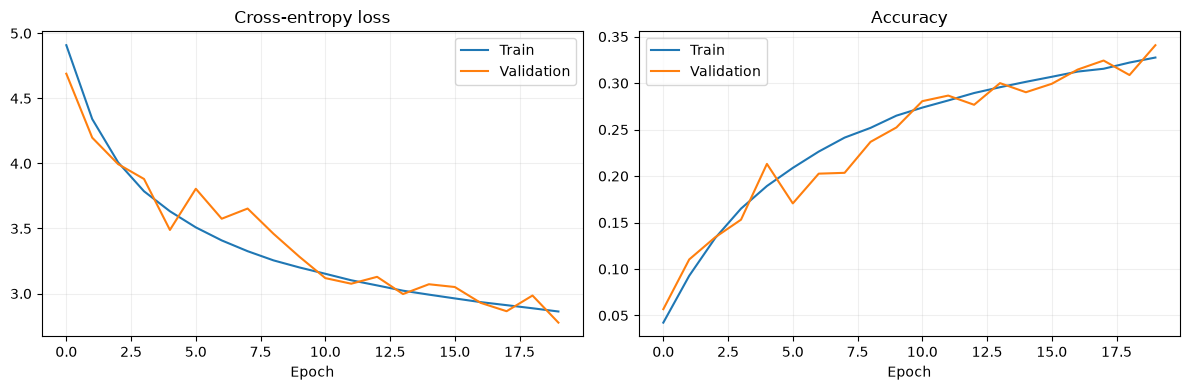

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history['train_loss'], label='Train')
axes[0].plot(history['val_loss'], label='Validation')
axes[0].set_title('Cross-entropy loss')
axes[1].plot(history['train_accuracy'], label='Train')
axes[1].plot(history['val_accuracy'], label='Validation')
axes[1].set_title('Accuracy')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.grid(alpha=0.2)
    ax.legend()
plt.tight_layout()
plt.show()

In [14]:
metrics = evaluate(
    model,
    val_loader,
    criterion,
    device=DEVICE,
    return_predictions=True
)

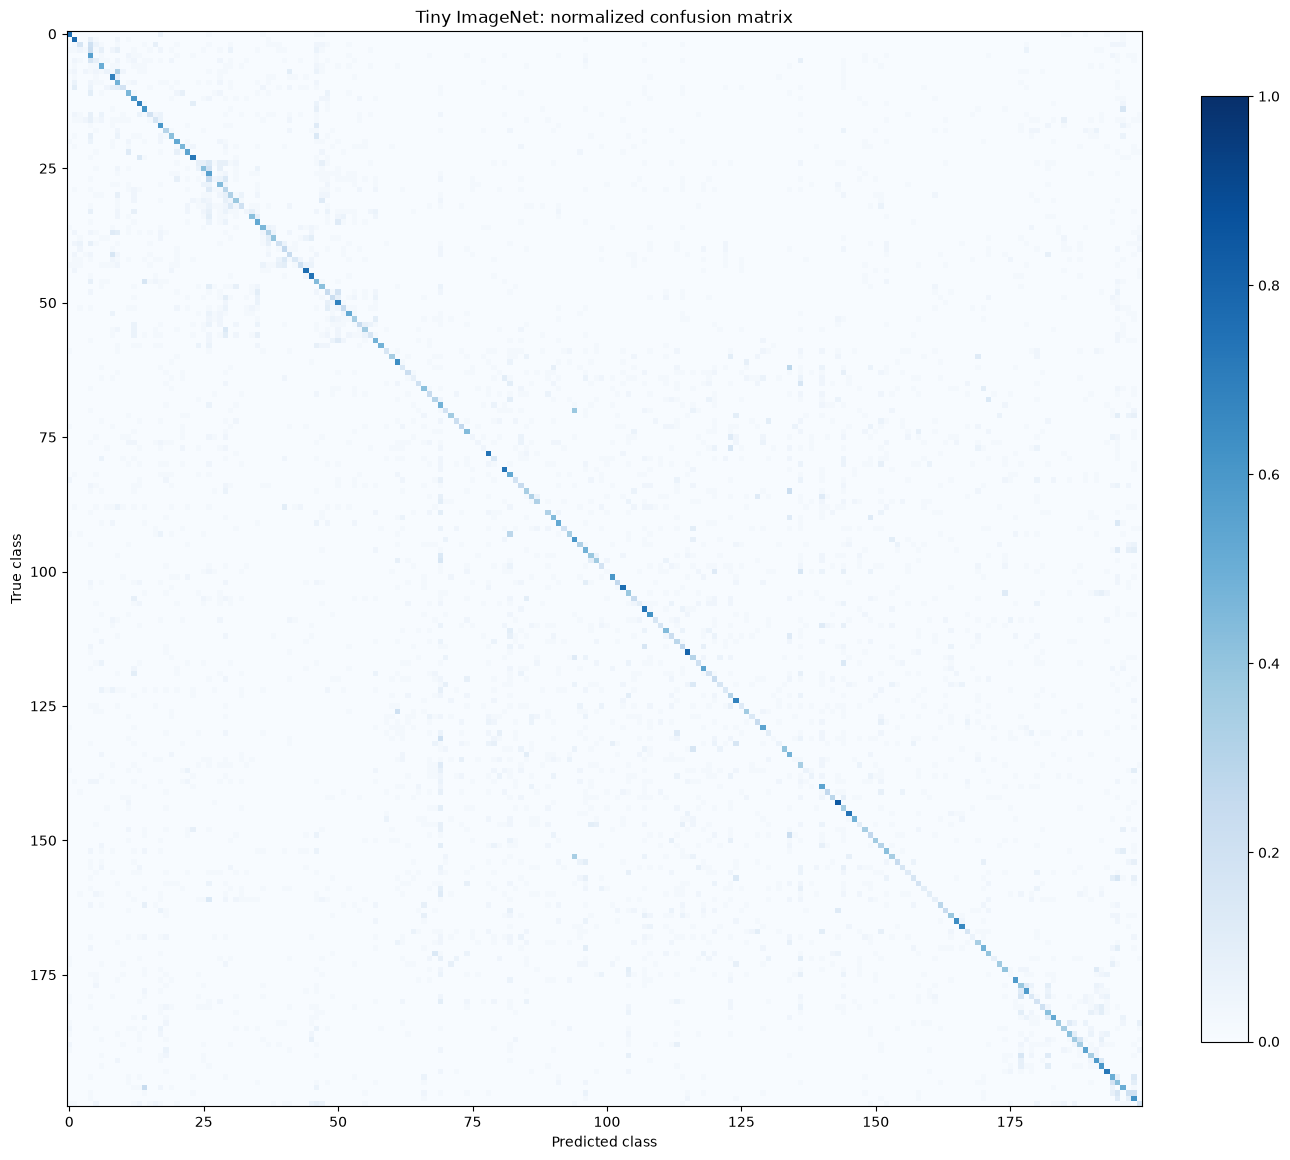

10 классов с наименьшим Recall:
 80 n02909870 | Recall=0.00%
 88 n02999410 | Recall=0.00%
139 n04067472 | Recall=0.00%
  3 n01644900 | Recall=2.00%
175 n04597913 | Recall=2.00%
135 n03983396 | Recall=2.00%
131 n03970156 | Recall=2.00%
100 n03255030 | Recall=2.00%
 77 n02883205 | Recall=4.00%
 27 n02099712 | Recall=4.00%


In [16]:
cm = confusion_matrix(
    metrics['y_true'],
    metrics['y_pred'],
    labels=np.arange(NUM_CLASSES),
    normalize='true'
)

fig, ax = plt.subplots(figsize=(13, 12))

im = ax.imshow(
    cm,
    cmap='Blues',
    vmin=0,
    vmax=1,
    interpolation='nearest'
)

fig.colorbar(im, ax=ax, fraction=0.04)

ax.set_title('Tiny ImageNet: normalized confusion matrix')
ax.set_xlabel('Predicted class')
ax.set_ylabel('True class')

plt.tight_layout()
plt.show()

recall = np.diag(cm)

idx_to_class = {
    i: name
    for name, i in class_to_idx.items()
}

worst = np.argsort(recall)[:10]

print('10 классов с наименьшим Recall:')

for idx in worst:
    print(
        f'{idx:3d} {idx_to_class[idx]} | '
        f'Recall={recall[idx]:.2%}'
    )

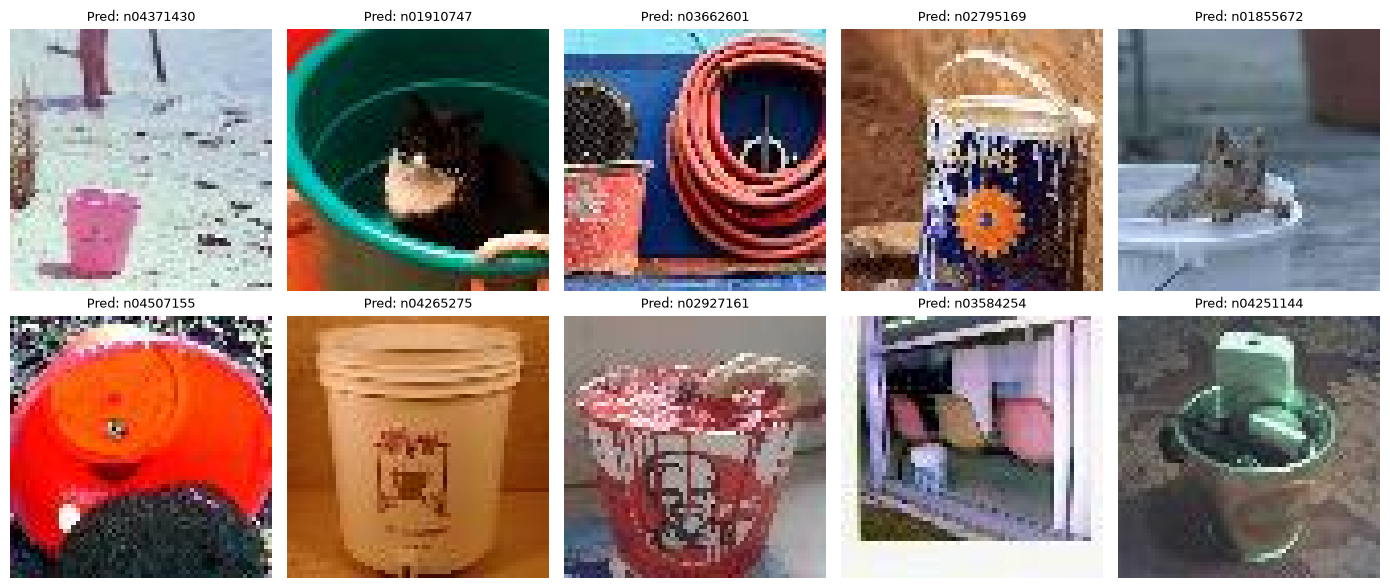

In [17]:
fig, axs = plt.subplots(2, 5, figsize=(14, 6))

worst_class = worst[0]

indices = np.where(metrics['y_true'] == worst_class)[0][:10]

for ax, idx in zip(axs.flat, indices):
    path, _ = val_samples[idx]

    with Image.open(path) as image:
        ax.imshow(image.convert('RGB'))

    pred = metrics['y_pred'][idx]

    ax.set_title(f"Pred: {idx_to_class[pred]}", fontsize=9)
    ax.axis('off')

plt.tight_layout()
plt.show()

In [18]:
restored_model = TinyCNN(NUM_CLASSES).to(DEVICE)
restored_model.load_state_dict(torch.load(CHECKPOINT_DIR / 'tiny_cnn_best.pth',
                                         map_location=DEVICE, weights_only=True))
print(evaluate(restored_model, val_loader, nn.CrossEntropyLoss(), DEVICE))


{'loss': 2.7767118419647216, 'accuracy': 0.3408}
